# 02 — Modelagem e Avaliação

**Objetivo:** comparar três famílias de modelos do Scikit-Learn com validação cruzada,
escolher o campeão e avaliá-lo no conjunto de teste.

| Modelo | Família | Papel |
|---|---|---|
| Regressão Logística | Linear | Baseline |
| Random Forest | Ensemble de árvores | Captura não linearidades |
| MLPClassifier | Rede neural | Rede simples (32 → 16 neurônios) |

Todos usam o **mesmo pré-processamento** (`src/preprocessing.build_preprocessor`) dentro de um
`Pipeline`, o que evita vazamento de dados entre os folds. Os hiperparâmetros estão em `src/models.py`.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # permite importar o pacote src/

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import RANDOM_STATE, NUMERIC_FEATURES, CATEGORICAL_FEATURES

np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", palette="deep")
FIG_DIR = Path("../docs/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
from src.train import load_and_split, compare_models
from src.config import CV_FOLDS

X_train, X_test, y_train, y_test = load_and_split()
print(f"Treino: {len(X_train)} | Teste: {len(X_test)}")

Treino: 5634 | Teste: 1409


## 1. Validação cruzada estratificada (5 folds)

In [3]:
results, oof_probas = compare_models(X_train, y_train)
cols = ["model", "cv_roc_auc_mean", "cv_roc_auc_std", "cv_f1_mean", "cv_recall_mean",
        "cv_precision_mean", "best_threshold", "oof_business_saving_pct"]
results[cols].round(4)

logistic_regression  AUC=0.8460 ± 0.0124 | F1=0.6293 | economia=24.6%


random_forest        AUC=0.8477 ± 0.0098 | F1=0.6323 | economia=24.0%


mlp                  AUC=0.8422 ± 0.0140 | F1=0.5771 | economia=24.1%


,model,cv_roc_auc_mean,cv_roc_auc_std,cv_f1_mean,cv_recall_mean,cv_precision_mean,best_threshold,oof_business_saving_pct
0,random_forest,0.8477,0.0098,0.6323,0.7926,0.5262,0.46,0.2399
1,logistic_regression,0.8460,0.0124,0.6293,0.8027,0.5178,0.52,0.2463
2,mlp,0.8422,0.0140,0.5771,0.5077,0.6702,0.25,0.2414


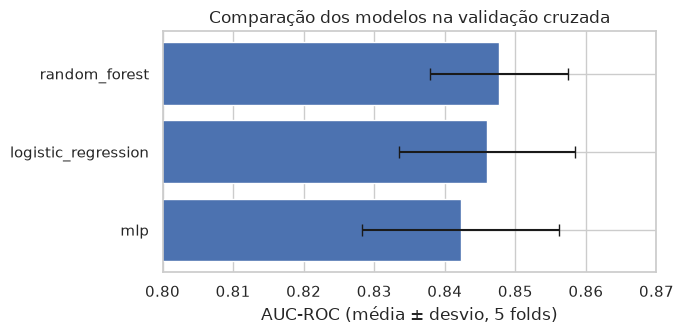

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(results["model"], results["cv_roc_auc_mean"], xerr=results["cv_roc_auc_std"], color="#4C72B0", capsize=4)
ax.set_xlim(0.80, 0.87); ax.set_xlabel("AUC-ROC (média ± desvio, 5 folds)")
ax.set_title("Comparação dos modelos na validação cruzada"); ax.invert_yaxis()
plt.tight_layout(); plt.savefig(FIG_DIR / "cv_comparison.png", dpi=120); plt.show()

**Leitura:** os três modelos ficam muito próximos. A diferença de AUC entre eles é **menor que o
desvio-padrão entre folds**, ou seja, não há um vencedor estatisticamente claro. Isso indica que
o sinal do dataset é em grande parte linear (contrato, tempo de casa, tipo de internet) e que
modelos mais complexos não conseguem extrair muito mais informação.

## 2. Limiar de decisão orientado ao negócio

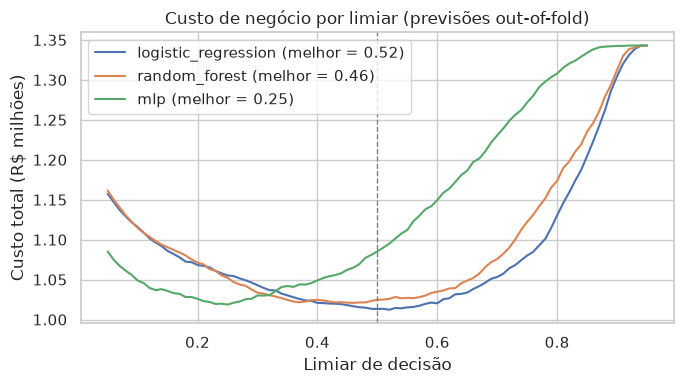

In [5]:
from src.evaluation import find_best_threshold

fig, ax = plt.subplots(figsize=(7, 4))
for name, oof in oof_probas.items():
    best, curve = find_best_threshold(y_train, oof, X_train["MonthlyCharges"])
    ax.plot(curve["threshold"], curve["cost"] / 1e6, label=f"{name} (melhor = {best})")
ax.axvline(0.5, ls="--", c="gray", lw=1)
ax.set_xlabel("Limiar de decisão"); ax.set_ylabel("Custo total (R$ milhões)")
ax.set_title("Custo de negócio por limiar (previsões out-of-fold)"); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "threshold_cost.png", dpi=120); plt.show()

Como perder um cliente custa muito mais (12 mensalidades) do que oferecer retenção (R$ 100),
vale a pena abordar mais clientes e aceitar falsos positivos para não deixar escapar quem vai
cancelar. O limiar ótimo depende de como cada modelo calibra as probabilidades: o MLP (treinado
sem peso de classe) produz probabilidades baixas e precisa de limiar ~0,25; a Regressão Logística
e a Random Forest, já treinadas com `class_weight="balanced"`, ficam perto de 0,5.

## 3. Avaliação final no conjunto de teste

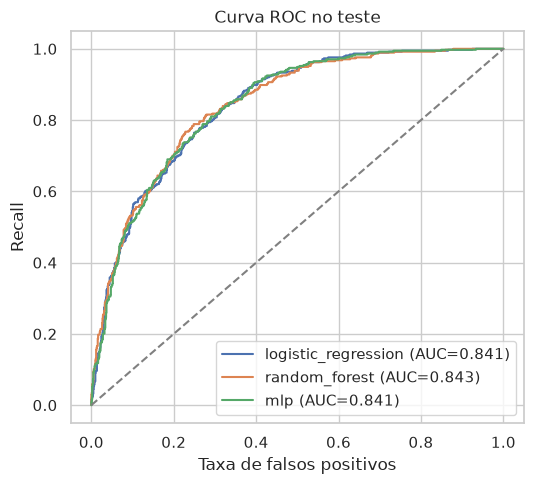

,model,threshold,roc_auc,f1,recall,precision,accuracy,business_saving_pct
0,logistic_regression,0.52,0.8415,0.6205,0.7781,0.5160,0.7473,0.2372
1,random_forest,0.46,0.8427,0.6207,0.8182,0.5000,0.7346,0.2272
2,mlp,0.25,0.8410,0.6159,0.7888,0.5051,0.7388,0.2313


In [6]:
from sklearn.metrics import roc_curve, ConfusionMatrixDisplay
from src.models import get_models, build_pipeline
from src.evaluation import technical_metrics, business_cost, cost_without_model

fitted, test_rows = {}, []
fig, ax = plt.subplots(figsize=(5.5, 5))
for name, model in get_models().items():
    pipe = build_pipeline(model).fit(X_train, y_train)
    fitted[name] = pipe
    proba = pipe.predict_proba(X_test)[:, 1]
    t = results.set_index("model").loc[name, "best_threshold"]
    m = technical_metrics(y_test, proba, t)
    m["business_saving_pct"] = 1 - business_cost(y_test, proba, X_test["MonthlyCharges"], t) / cost_without_model(y_test, X_test["MonthlyCharges"])
    test_rows.append({"model": name, "threshold": t, **m})
    fpr, tpr, _ = roc_curve(y_test, proba)
    ax.plot(fpr, tpr, label=f"{name} (AUC={m['roc_auc']:.3f})")
ax.plot([0, 1], [0, 1], "--", c="gray"); ax.set_xlabel("Taxa de falsos positivos"); ax.set_ylabel("Recall")
ax.set_title("Curva ROC no teste"); ax.legend(); plt.tight_layout()
plt.savefig(FIG_DIR / "roc_test.png", dpi=120); plt.show()

test_results = pd.DataFrame(test_rows)
test_results.round(4)

## 4. Tabela comparativa final

In [7]:
comparison = results[["model", "cv_roc_auc_mean", "cv_roc_auc_std", "cv_f1_mean"]].merge(
    test_results[["model", "threshold", "roc_auc", "f1", "recall", "precision", "business_saving_pct"]], on="model")
comparison.columns = ["Modelo", "AUC CV (média)", "AUC CV (desvio)", "F1 CV (limiar 0.5)",
                      "Limiar", "AUC teste", "F1 teste", "Recall teste", "Precision teste", "Economia teste"]
comparison.round(4)

,Modelo,AUC CV (média),AUC CV (desvio),F1 CV (limiar 0.5),Limiar,AUC teste,F1 teste,Recall teste,Precision teste,Economia teste
0,random_forest,0.8477,0.0098,0.6323,0.46,0.8427,0.6207,0.8182,0.5000,0.2272
1,logistic_regression,0.8460,0.0124,0.6293,0.52,0.8415,0.6205,0.7781,0.5160,0.2372
2,mlp,0.8422,0.0140,0.5771,0.25,0.8410,0.6159,0.7888,0.5051,0.2313


## 5. Escolha do modelo campeão

**Critério definido antes dos experimentos:** maior AUC-ROC média na validação cruzada.
Pelo critério, o campeão é a **Random Forest**.

Pontos a considerar (registrados no Model Card):
- A vantagem sobre o baseline é pequena (≈ 0,002 de AUC) e está dentro da variação entre folds.
- A Random Forest tem o **menor desvio-padrão entre folds** (mais estável) e o **maior recall no teste**,
  o que é desejável quando deixar um churn escapar é o erro mais caro.
- No teste, a Regressão Logística teve **economia de negócio um pouco maior** (23,7% vs 22,7%),
  porque aborda menos falsos positivos. Ela seria uma escolha igualmente defensável, sobretudo se a
  prioridade fosse interpretabilidade. Mantivemos o critério definido a priori para não "escolher
  olhando o teste".
- O MLP não trouxe ganho que justificasse sua complexidade.

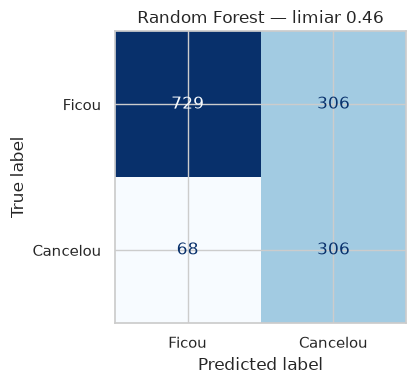

In [8]:
champion = fitted["random_forest"]
t = results.set_index("model").loc["random_forest", "best_threshold"]
proba = champion.predict_proba(X_test)[:, 1]
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, (proba >= t).astype(int),
    display_labels=["Ficou", "Cancelou"], cmap="Blues", ax=ax, colorbar=False)
ax.set_title(f"Random Forest — limiar {t}"); plt.tight_layout()
plt.savefig(FIG_DIR / "confusion_matrix.png", dpi=120); plt.show()

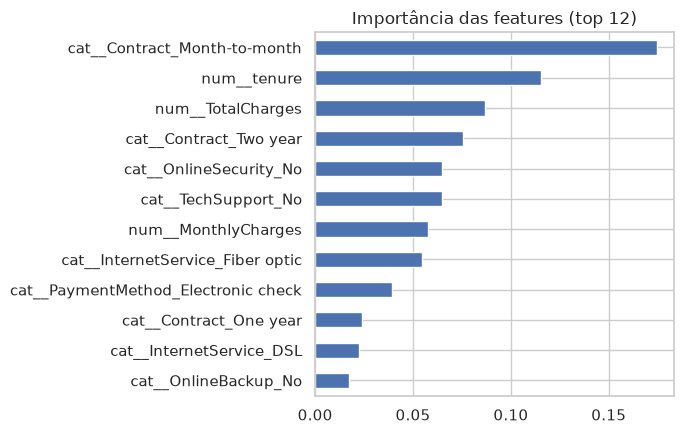

In [9]:
importances = pd.Series(
    champion.named_steps["model"].feature_importances_,
    index=champion.named_steps["preprocessor"].get_feature_names_out(),
).sort_values(ascending=False).head(12)
fig, ax = plt.subplots(figsize=(7, 4.5))
importances.sort_values().plot.barh(ax=ax, color="#4C72B0")
ax.set_title("Importância das features (top 12)"); plt.tight_layout()
plt.savefig(FIG_DIR / "feature_importance.png", dpi=120); plt.show()

## 6. Análise de viés por grupo

Verificamos se o modelo erra mais para algum grupo demográfico.

In [10]:
from sklearn.metrics import recall_score, roc_auc_score
pred = (proba >= t).astype(int)
rows = []
for col in ["gender", "SeniorCitizen", "Partner", "Dependents"]:
    for value in X_test[col].unique():
        mask = (X_test[col] == value).values
        rows.append({"grupo": f"{col}={value}", "clientes": mask.sum(),
                     "churn_real": y_test[mask].mean(), "auc": roc_auc_score(y_test[mask], proba[mask]),
                     "recall": recall_score(y_test[mask], pred[mask]), "taxa_abordados": pred[mask].mean()})
pd.DataFrame(rows).round(3)

,grupo,clientes,churn_real,auc,recall,taxa_abordados
0,gender=Male,722,0.251,0.841,0.845,0.440
1,gender=Female,687,0.281,0.846,0.793,0.428
2,SeniorCitizen=0,1187,0.233,0.844,0.783,0.388
3,SeniorCitizen=1,222,0.441,0.779,0.918,0.680
4,Partner=Yes,673,0.187,0.848,0.698,0.287
5,Partner=No,736,0.337,0.822,0.879,0.569
6,Dependents=Yes,431,0.165,0.845,0.648,0.230
7,Dependents=No,978,0.310,0.829,0.858,0.525


**Leitura:**
- **Gênero:** AUC praticamente igual entre homens e mulheres. Sem sinal de viés.
- **Idosos (`SeniorCitizen=1`):** o modelo **ordena pior** esse grupo (AUC ≈ 0,78 vs 0,84) e aborda
  ~68% deles. Parte disso acompanha o churn real maior do grupo (44%), mas a queda de AUC indica que
  o modelo é menos confiável para idosos. É uma limitação registrada no Model Card.
- Clientes sem parceiro ou dependentes também são mais abordados, coerente com o churn real maior.

## 7. Salvar o modelo

O treino final e o salvamento são feitos pelo script de produção, não pelo notebook:

```bash
python -m src.train
```

Ele salva `models/churn_model.joblib` (pipeline + limiar), `models/metrics.json` e acrescenta
os resultados em `models/experiments.csv` (registro dos experimentos).